# Differential Geometry and Topology for Geometric Learning

**AI Mathematics · 7. Advanced Topics**

Build intuition for manifolds, tangent directions, geodesics, curvature, and topology without requiring advanced geometric machinery.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Distinguish Euclidean coordinates from manifold structure.
- Understand tangent directions and geodesic distance conceptually.
- Recognize why geometry and topology matter for non-Euclidean data.

In [1]:
import numpy as np

## 1. What is a manifold?
A manifold is a space that locally resembles Euclidean space, even if its global shape is curved. Examples include the circle and sphere. Angles, rotations, molecular configurations, and surface meshes may naturally live on such spaces instead of unconstrained Euclidean coordinate spaces.

In [2]:
import numpy as np

# Points on the unit circle: they satisfy x^2 + y^2 = 1.
theta = np.linspace(0, 2*np.pi, 8, endpoint=False)
points = np.column_stack([np.cos(theta), np.sin(theta)])
print(points[:3])
print("constraint values:", np.sum(points**2, axis=1))

[[1.00000000e+00 0.00000000e+00]
 [7.07106781e-01 7.07106781e-01]
 [6.12323400e-17 1.00000000e+00]]
constraint values: [1. 1. 1. 1. 1. 1. 1. 1.]


## 2. Tangent directions
A tangent vector describes a locally valid direction of movement. For the unit circle parameterized by \(x(\theta)=(\cos\theta,\sin\theta)\), the tangent is \((-\sin\theta,\cos\theta)\), which is orthogonal to the radius vector. In manifold optimization, updates may need to remain tangent and then be mapped back to the manifold.

In [3]:
theta0 = np.pi/4
radius = np.array([np.cos(theta0), np.sin(theta0)])
tangent = np.array([-np.sin(theta0), np.cos(theta0)])
print("radius dot tangent:", radius @ tangent)
print("tangent norm:", np.linalg.norm(tangent))

radius dot tangent: -1.0146536357569526e-17
tangent norm: 1.0


## 3. Euclidean distance versus geodesic distance
Euclidean distance measures a straight line through the ambient space. Geodesic distance measures the shortest path constrained to the manifold. On a unit circle, the shorter arc between two points has length equal to the smaller angular separation (in radians), while chord distance is \(2\sin(\Delta\theta/2)\).

In [4]:
theta1, theta2 = 0.0, 2*np.pi/3
delta = abs(theta1-theta2)
arc = min(delta, 2*np.pi-delta)
chord = np.linalg.norm(np.array([np.cos(theta1),np.sin(theta1)]) - np.array([np.cos(theta2),np.sin(theta2)]))
print("arc distance:", arc)
print("chord distance:", chord)

arc distance: 2.0943951023931953
chord distance: 1.7320508075688772


## 4. Curvature and topology intuition
Curvature describes how a space bends locally; topology studies properties such as connectedness and holes that remain under continuous deformation. These are different concepts. A graph, point cloud, surface, or rotation group may require metrics and operations adapted to its structure.

In [5]:
# A simple circle has a hole; a filled disk does not.
# These points only visualize the circle constraint numerically.
angles = np.linspace(0, 2*np.pi, 100, endpoint=False)
circle = np.column_stack([np.cos(angles), np.sin(angles)])
print("mean radius:", np.mean(np.linalg.norm(circle, axis=1)))
print("points on circle:", circle.shape[0])

mean radius: 1.0
points on circle: 100


## 5. Why this matters in ML
Geometric deep learning uses symmetries and structure to define meaningful transformations, neighborhoods, and operations. In robotics, 3D vision, chemistry, and physical simulation, Euclidean layers may ignore constraints such as rotation invariance or valid configuration spaces. Advanced manifold methods require careful choice of metric and coordinate chart.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: Euclidean distance versus distance along a manifold

Points on a curved surface can be close in ambient coordinates but far apart when movement is restricted to the surface. On a unit circle, the straight-line chord distance between two points is \(2\sin(	heta/2)\), while the shorter arc distance is \(	heta\) for \(0\le	heta\le\pi\). This is a simple example of extrinsic versus intrinsic distance.

22_differential_geometry_and_topology.ipynb:cell14:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
22_differential_geometry_and_topology.ipynb:cell14:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


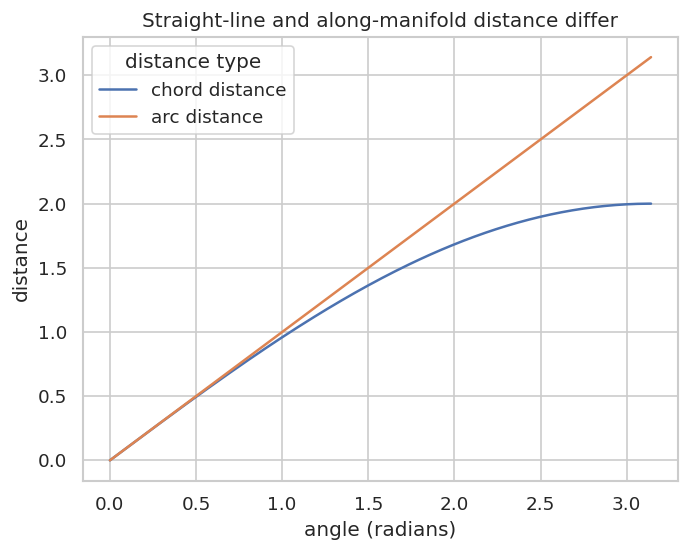

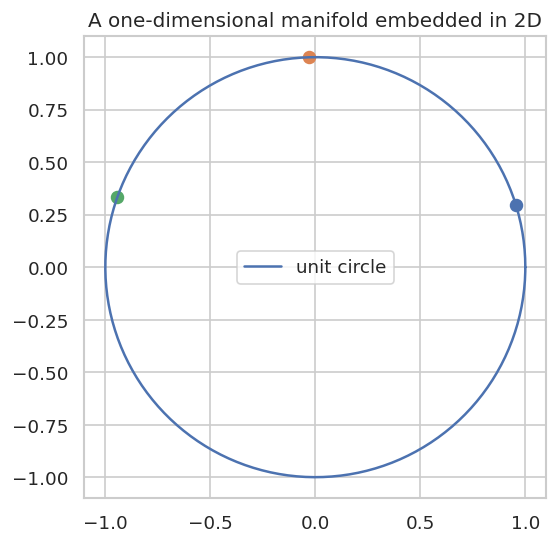

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_geo_theta = np.linspace(0, np.pi, 200)
viz_geo_chord = 2*np.sin(viz_geo_theta/2)
viz_geo_arc = viz_geo_theta
viz_geo_df = pd.DataFrame({"angle (radians)": viz_geo_theta, "chord distance": viz_geo_chord, "arc distance": viz_geo_arc})
sns.lineplot(data=viz_geo_df.melt(id_vars="angle (radians)", var_name="distance type", value_name="distance"), x="angle (radians)", y="distance", hue="distance type")
plt.title("Straight-line and along-manifold distance differ"); plt.show()
viz_geo_t = np.linspace(0, 2*np.pi, 300)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(np.cos(viz_geo_t), np.sin(viz_geo_t), label="unit circle")
for a in [0.3, 1.6, 2.8]:
    ax.scatter(np.cos(a), np.sin(a), s=50)
ax.set_aspect("equal", adjustable="box"); ax.legend(); ax.set_title("A one-dimensional manifold embedded in 2D"); plt.show()

### Tangent vectors are local directions

The tangent vector to \(r(t)=(\cos t,\sin t)\) is \(r'(t)=(-\sin t,\cos t)\). It points along the circle rather than directly away from the origin. Tangent spaces provide local linear approximations to curved manifolds; topology studies properties preserved by continuous deformation, which are not captured by distances alone.

22_differential_geometry_and_topology.ipynb:cell16:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,t,x,y,tangent x,tangent y
0,0.5,0.878,0.479,-0.479,0.878
1,1.5,0.071,0.997,-0.997,0.071
2,2.5,-0.801,0.598,-0.598,-0.801


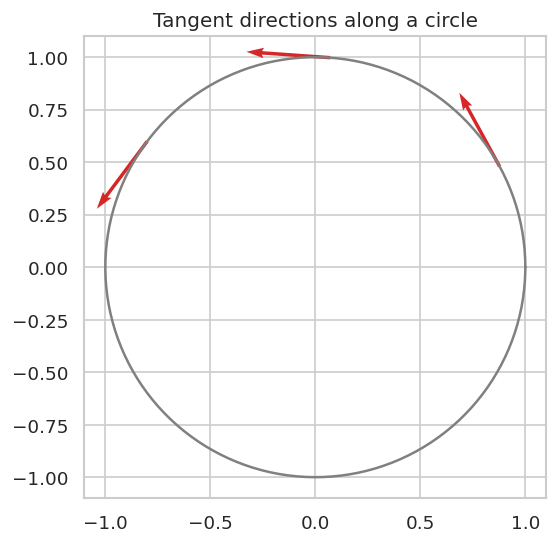

In [7]:
viz_geo_tangent_t = np.array([0.5, 1.5, 2.5])
viz_geo_points = np.column_stack([np.cos(viz_geo_tangent_t), np.sin(viz_geo_tangent_t)])
viz_geo_tangents = np.column_stack([-np.sin(viz_geo_tangent_t), np.cos(viz_geo_tangent_t)])
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(np.cos(viz_geo_t), np.sin(viz_geo_t), color="0.5")
ax.quiver(viz_geo_points[:,0], viz_geo_points[:,1], viz_geo_tangents[:,0], viz_geo_tangents[:,1], angles="xy", scale_units="xy", scale=2.5, color="tab:red")
ax.set_aspect("equal", adjustable="box"); ax.set_title("Tangent directions along a circle"); plt.show()
display(pd.DataFrame({"t": viz_geo_tangent_t, "x": viz_geo_points[:,0], "y": viz_geo_points[:,1], "tangent x": viz_geo_tangents[:,0], "tangent y": viz_geo_tangents[:,1]}).round(3))

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Compute the unit-circle tangent at theta=0 and verify it is orthogonal to the radius.

In [8]:
theta = 0.0
r = np.array([np.cos(theta), np.sin(theta)])
t = np.array([-np.sin(theta), np.cos(theta)])
print(r, t, r @ t)

[1. 0.] [-0.  1.] 0.0


### Exercise 2
Exercise 2: Compare arc length and chord length for a quarter circle.

In [9]:
delta = np.pi/2
print("arc:", delta, "chord:", 2*np.sin(delta/2))

arc: 1.5707963267948966 chord: 1.414213562373095


## Key takeaways
- Manifolds can be locally Euclidean but globally curved.
- Geodesic distance respects the space’s constraints; Euclidean distance may not.
- Geometric learning benefits from operations compatible with the structure and symmetries of the data.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.